# DoE Tensile Delivery (2026-09-03) — Data Processing

Driver for the **first delivery that follows the DoE** handed to Anupam in August
(received 2026-09-11, tests run 2026-09-03). It contains Instron raw exports of the tensile
tests for the formulations in [`doe/doe_formulations.xlsx`](../doe/doe_formulations.xlsx).
All logic lives in the [`utils/`](../utils) package (new module `utils/instron.py`); this
notebook orchestrates and displays.

| | |
|---|---|
| Raw delivery | `raw_data/09_03_26/nu-formulations-tensile test-….zip` — one folder per formulation, one CSV per specimen |
| Tables / curves | `processed_data/tensile_doe/` — *only when the cell's save switch is on* |
| Figures | `processed_data/figures/` — *only when the cell's save switch is on* |

**Nothing is written to `processed_data/` by default.** Every cell that can save a file starts with its own
switch and file name — `SAVE_FIG` / `FIG_NAME` (figure), `SAVE_CSV` / `CSV_NAME`, `SAVE_XLSX` / `XLSX_NAME` (tables),
`SAVE_CURVES` / `CURVES_DIR` (per-specimen curves). Set the switch to `True` and re-run that cell to write the file
under the name you chose; the extension is added for you (`.png`, `.csv`, `.xlsx`) unless the name already has one —
e.g. `FIG_NAME = "pareto_v2.pdf"` saves a PDF. Re-using an existing name overwrites that file.

**Sections:** 1 · DoE recap — 2 · Delivery inventory — 3 · Received vs. provided DoE —
4 · Curve parsing & metrics — 5 · Curves — 6 · Per-formulation statistics —
7 · Properties vs. design factors — 8 · Objective correlations & Pareto front — 9 · Modeling-ready dataset —
10 · Outputs — Summary

In [1]:
# Re-import edited utils/ modules before every cell -> no kernel restart after changing them.
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path


# Make the project root importable whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "utils").exists() and (ROOT.parent / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import config, io, instron, tensile, plots

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

p = config.paths(ROOT)
config.ensure_dirs(p)
EXTRACTED = io.extract_zip(p.raw_doe)
ZIP = sorted(p.raw_doe.glob("*.zip"))[0]
print("project root :", p.root)
print("delivery     :", ZIP.name)
print("extracted to :", EXTRACTED.relative_to(p.root))

project root : /data/zhq7531/IDEAL/UIC_NU_new/multi_task
delivery     : nu-formulations-tensile test-20260911T195423Z-1-001.zip
extracted to : raw_data/09_03_26/extracted


---
## 1 — The provided DoE (recap)

Generated in `data_processing_v2.ipynb` (optimized Latin hypercube, `utils/doe.py`) and handed off as
`doe/doe_formulations.xlsx` + `doe/doe_measurement_plan.xlsx`.

| Factor | Type | Range / levels |
|---|---|---|
| Polymer system | categorical (≥ 3 levels for LVGP) | PP+PAL, HDPE+PAL, TPU+PAL |
| PAL content | continuous | 10 – 50 % |
| Extrusion temperature | continuous | 180 – 240 °C |

* **12 formulations**, balanced 4 per polymer; PAL % and temperature sampled space-fillingly (temperature rounded to 5 °C).
* **Recycle level is not a design factor**: every formulation is swept through the 1× / 5× / 10× degradation
  series → **36 measurements** in the plan (aimed at the rheology; virgin 0× from literature).
* Per sample requested: rheology (shear-rate / frequency / amplitude sweeps) and **tensile with ≥ 3 replicates**
  (UTS, Young's modulus, toughness).

In [2]:
design = pd.read_csv(p.doe / "doe_formulations.csv")
plan = pd.read_csv(p.doe / "doe_measurement_plan.csv")
print(f"{len(design)} formulations × {plan['recycle_level'].nunique()} recycle levels "
      f"{sorted(int(x) for x in plan['recycle_level'].unique())} = {len(plan)} planned measurements")
print("polymer balance:", design["polymer_system"].value_counts().to_dict())
design

12 formulations × 3 recycle levels [1, 5, 10] = 36 planned measurements
polymer balance: {'HDPE+PAL': 4, 'PP+PAL': 4, 'TPU+PAL': 4}


,formulation,polymer_system,PAL_pct,extrusion_temp_C
0,1,HDPE+PAL,49,220
1,2,HDPE+PAL,23,235
2,3,PP+PAL,15,225
3,4,PP+PAL,28,180
4,5,TPU+PAL,37,230
5,6,PP+PAL,41,205
6,7,TPU+PAL,11,200
7,8,TPU+PAL,46,185
8,9,HDPE+PAL,35,200
9,10,HDPE+PAL,19,195


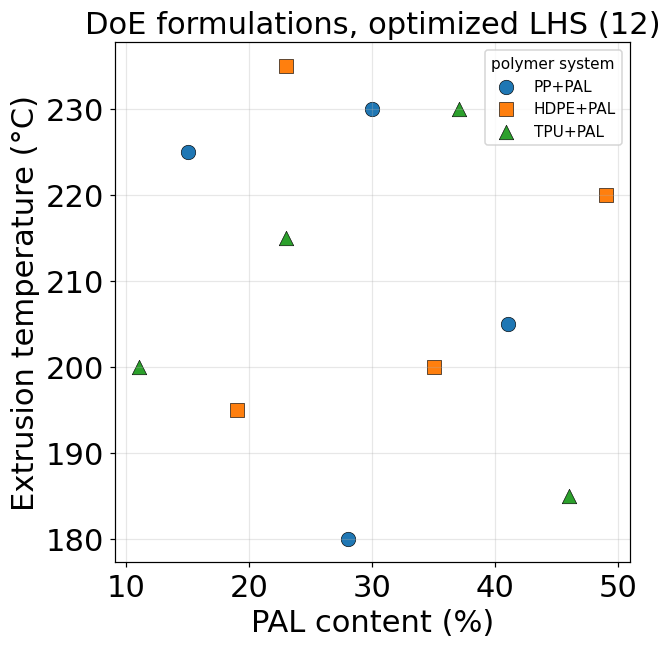

In [3]:
plots.doe_scatter(design)

---
## 2 — What arrived: delivery inventory

The zip holds one Bluehill export folder per formulation, `nu_samples-f<NN>.is_tens_RawData/`, each with
`Specimen_RawData_<i>.csv` per replicate. Three formulations also have a **follow-up folder** `f<NN>_1`
(one extra specimen each, exported about an hour after the main run) — treated as additional replicates and
flagged with `session = 1`. Formulation numbers map 1:1 onto the DoE `formulation` column.

In [4]:
SAVE_CSV = False                      # True -> write the catalogue to processed_data/tensile_doe/
CSV_NAME = "delivery_catalogue"

cat = instron.catalogue(EXTRACTED, ZIP)
if SAVE_CSV:
    cat.drop(columns="path").to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
print(f"{len(cat)} specimen files · {cat['formulation'].nunique()} formulations · "
      f"{(cat['session'] > 0).sum()} follow-up specimens")
(cat.groupby("formulation")
    .agg(specimens=("specimen_id", "count"), sessions=("session", "nunique"),
         folders=("folder", lambda s: ", ".join(sorted(set(s)))),
         exported=("exported_at", lambda s: " / ".join(sorted({t.strftime('%H:%M') for t in s})))))

30 specimen files · 9 formulations · 3 follow-up specimens


,specimens,sessions,folders,exported
formulation,,,,
1,3,1,nu_samples-f01.is_tens_RawData,06:23
2,4,2,"nu_samples-f02.is_tens_RawData, nu_samples-f02...",06:33 / 07:51
3,5,1,nu_samples-f03.is_tens_RawData,07:32
4,3,1,nu_samples-f04.is_tens_RawData,07:01
6,3,1,nu_samples-f06.is_tens_RawData,07:07
8,1,1,nu_samples-f08.is_tens_RawData,06:56
9,3,1,nu_samples-f09.is_tens_RawData,06:19
10,4,2,"nu_samples-f10.is_tens_RawData, nu_samples-f10...",06:41 / 07:43
12,4,2,"nu_samples-f12.is_tens_RawData, nu_samples-f12...",07:16 / 07:49


---
## 3 — Received vs. provided DoE

Side-by-side of what the plan asked for and what this delivery contains, then the per-formulation coverage.

In [5]:
SAVE_CSV = False                      # True -> write the coverage table to processed_data/tensile_doe/
CSV_NAME = "doe_coverage"

cov = instron.coverage(design, cat)
if SAVE_CSV:
    cov.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
cmp = instron.compare_to_plan(design, plan, cov, cat)

comparison = pd.DataFrame({
    "provided DoE": [
        cmp["planned_formulations"], cmp["planned_polymer_balance"],
        f"{cmp['pal_range_planned'][0]}–{cmp['pal_range_planned'][1]} %",
        f"{cmp['temp_range_planned'][0]}–{cmp['temp_range_planned'][1]} °C",
        cmp["planned_recycle_levels"], f"≥ 3 per formulation (≥ {3 * cmp['planned_formulations']})",
        cmp["planned_measurements"]],
    "received 2026-09-03": [
        cmp["received_formulations"], cmp["received_polymer_balance"],
        f"{cmp['pal_range_received'][0]}–{cmp['pal_range_received'][1]} %",
        f"{cmp['temp_range_received'][0]}–{cmp['temp_range_received'][1]} °C",
        cmp["received_recycle_levels"],
        f"{cmp['received_specimens']} ({cmp['formulations_with_ge3_reps']} formulations with ≥ 3)",
        "none in this delivery"],
}, index=["formulations", "polymer balance", "PAL range", "temperature range",
          "recycle levels", "tensile specimens", "rheology runs"])
print("missing formulations:", cmp["missing_formulations"], "→", cmp["missing_by_polymer"])
print("follow-up sessions  :", cmp["formulations_with_followup_session"])
comparison

missing formulations: [5, 7, 11] → {'TPU+PAL': 3}
follow-up sessions  : [2, 10, 12]


,provided DoE,received 2026-09-03
formulations,12,9
polymer balance,"{'HDPE+PAL': 4, 'PP+PAL': 4, 'TPU+PAL': 4}","{'HDPE+PAL': 4, 'PP+PAL': 4, 'TPU+PAL': 1}"
PAL range,11–49 %,15–49 %
temperature range,180–235 °C,180–235 °C
recycle levels,"[1, 5, 10]",not encoded in delivery
tensile specimens,≥ 3 per formulation (≥ 36),30 (8 formulations with ≥ 3)
rheology runs,36,none in this delivery


In [6]:
cov[["formulation", "polymer_system", "PAL_pct", "extrusion_temp_C",
     "n_specimens", "n_main", "n_followup", "status"]]

,formulation,polymer_system,PAL_pct,extrusion_temp_C,n_specimens,n_main,n_followup,status
0,1,HDPE+PAL,49,220,3,3,0,received
1,2,HDPE+PAL,23,235,4,3,1,received
2,3,PP+PAL,15,225,5,5,0,received
3,4,PP+PAL,28,180,3,3,0,received
4,5,TPU+PAL,37,230,0,0,0,missing
5,6,PP+PAL,41,205,3,3,0,received
6,7,TPU+PAL,11,200,0,0,0,missing
7,8,TPU+PAL,46,185,1,1,0,received (< 3 reps)
8,9,HDPE+PAL,35,200,3,3,0,received
9,10,HDPE+PAL,19,195,4,3,1,received


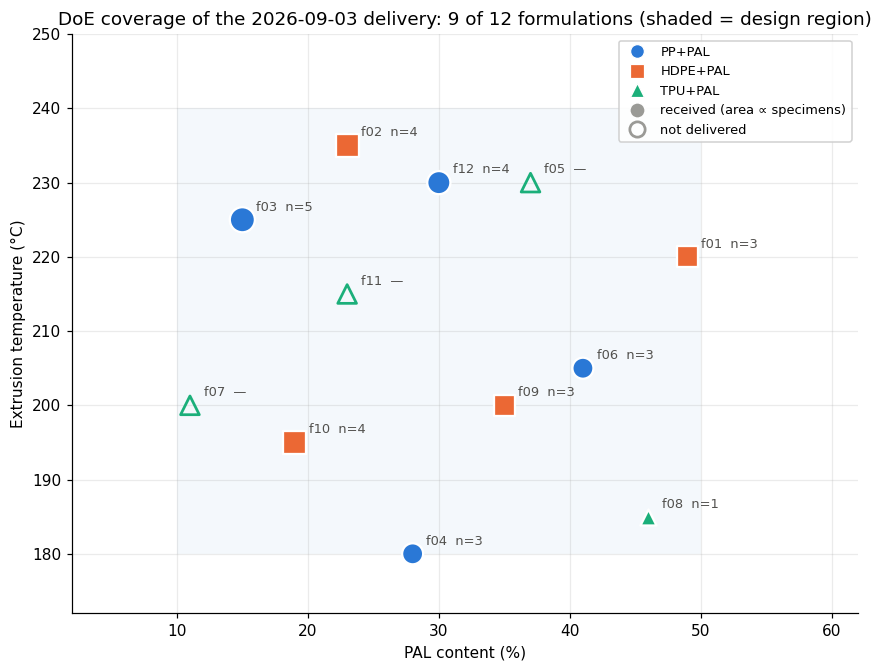

In [7]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_coverage"

plots.doe_coverage(cov, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Gaps against the plan**

* **3 of 12 formulations are missing — all TPU+PAL** (f05, f07, f11). The only TPU point, f08, has a
  **single specimen**, so the TPU level of the categorical factor is essentially unobserved
  (LVGP needs ≥ 3 polymer levels with data).
* PP+PAL and HDPE+PAL are complete (4 + 4 formulations, 3–5 specimens each; f02, f10, f12 got a
  follow-up specimen). Coverage of the PAL × temperature region is otherwise as designed.
* **Recycle level is not encoded** anywhere in the delivery (folder names, metadata). These are presumably
  the as-extruded (1×) samples — to confirm with Anupam; the dataset carries an empty `recycle_level` column.
* **No rheology** in this delivery (the 36-run plan is rheology-centric), and no 5× / 10× tensile.
* Specimens are **filaments** (nominal ⌀ 1.75 mm, 100 mm gauge) — the measured diameter varies 1.40–2.05 mm
  between replicates, which is one obvious source of replicate scatter.

---
## 4 — Parse the raw curves → tidy curves + metrics

Unlike the June workbook, the scalar properties are **not pre-computed** by the instrument; `utils/instron.py`
derives them from each raw `Time, Extension, Load, Strain, Stress` series:

| Metric | Rule |
|---|---|
| **UTS** | peak stress |
| **Young's modulus** | least-squares chord slope over the first rise through **10–40 % of UTS** (above the toe, below yield) — *for TPU this is a secant, not an initial tangent* |
| **Toe offset** | strain where that chord crosses zero stress; subtracted from the reported strains (ASTM D638-style) |
| **Break** | first post-peak sample below **5 % of UTS** — the machine keeps logging after fracture, so the last row is *not* the break |
| **Toughness** | $\int_0^{\varepsilon_\text{break}} \max(\sigma, 0)\, d\varepsilon$ (trapezoid), MJ/m³ |

Strain is crosshead extension / 100 mm gauge (no extensometer), so moduli are comparable within this batch
but underestimate the true material modulus. With `SAVE_CURVES = True` the per-specimen tidy curves go to `tensile_doe/<CURVES_DIR>/`.

In [8]:
SAVE_CURVES = False                   # True -> one tidy CSV per specimen (<specimen_id>.csv) in the folder below
CURVES_DIR = "curves"                 # sub-folder of processed_data/tensile_doe/
SAVE_CSV = False                      # True -> write the per-specimen metrics table to processed_data/tensile_doe/
CSV_NAME = "tensile_doe_summary"

curves, _raw = instron.load_delivery(cat, p.tensile_doe / CURVES_DIR if SAVE_CURVES else None)
summary = instron.attach_doe(_raw, design)
if SAVE_CSV:
    summary.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
print(f"parsed {len(curves)} specimens · {summary['formulation'].nunique()} formulations · "
      f"{sum(len(c) for c in curves.values())} data points")
summary[["specimen_id", "polymer_system", "pal_pct", "extr_temp_C", "session", "diameter_mm",
         "young_modulus_MPa", "max_tensile_stress_MPa", "strain_at_uts", "strain_at_break",
         "toughness_MJ_m3", "n_points", "n_points_to_break"]].round(4)

parsed 30 specimens · 9 formulations · 16466 data points


,specimen_id,polymer_system,pal_pct,extr_temp_C,session,diameter_mm,young_modulus_MPa,max_tensile_stress_MPa,strain_at_uts,strain_at_break,toughness_MJ_m3,n_points,n_points_to_break
0,f01_s1,HDPE+PAL,49,220,0,1.75,438.3262,7.3121,0.0374,0.0479,0.2559,321,287
1,f01_s2,HDPE+PAL,49,220,0,2.05,310.8672,5.4587,0.0495,0.0597,0.2519,385,351
2,f01_s3,HDPE+PAL,49,220,0,2.05,292.1215,5.3401,0.0418,0.0570,0.2285,416,360
3,f02_s1,HDPE+PAL,23,235,0,1.40,930.2024,13.6502,0.0202,0.0241,0.1929,274,153
4,f02_s2,HDPE+PAL,23,235,0,1.70,899.4813,11.8038,0.0222,0.0315,0.2183,269,186
5,f02_s3,HDPE+PAL,23,235,0,1.75,643.3736,8.0387,0.0146,0.0321,0.1546,267,195
6,f02_1_s1,HDPE+PAL,23,235,1,1.65,761.3102,9.6582,0.0233,0.0365,0.2138,239,220
7,f03_s1,PP+PAL,15,225,0,1.70,845.4525,13.2356,0.0283,0.0361,0.3482,313,211
8,f03_s2,PP+PAL,15,225,0,1.40,466.1416,12.1992,0.0388,0.0446,0.3655,422,267
9,f03_s3,PP+PAL,15,225,0,1.75,661.0346,9.3852,0.0178,0.0205,0.1222,338,125


### 4.1 Extraction QA and test conditions
Fit quality of the modulus chord, size of the toe correction, and the (constant) test conditions.

In [9]:
qa = summary[["specimen_id", "polymer_system", "modulus_r2", "modulus_fit_points",
              "toe_offset_strain", "strain_at_break_raw", "strain_at_break"]]
print(f"modulus chord R²  : min {qa['modulus_r2'].min():.4f} · median {qa['modulus_r2'].median():.4f} "
      f"(lowest: {qa.loc[qa['modulus_r2'].idxmin(), 'specimen_id']})")
print(f"toe offset strain : max |offset| {qa['toe_offset_strain'].abs().max():.4f} · "
      f"median {qa['toe_offset_strain'].abs().median():.4f} (vs. break strains of {summary['strain_at_break_raw'].min():.3f}–{summary['strain_at_break_raw'].max():.3f})")
print(f"gauge length      : {summary['gauge_length_mm'].unique()} mm")
print(f"crosshead rate    : {summary['crosshead_rate_mm_min'].round(2).unique()} mm/min")
print(f"diameter          : {summary['diameter_mm'].min():.2f}–{summary['diameter_mm'].max():.2f} mm "
      f"(area = π d²/4, used by the instrument for stress)")
(summary.groupby(["formulation", "polymer_system"])
        .agg(n=("specimen_id", "count"), d_min=("diameter_mm", "min"), d_max=("diameter_mm", "max"),
             r2_min=("modulus_r2", "min"), fit_pts_min=("modulus_fit_points", "min"))
        .round(4))

modulus chord R²  : min 0.9791 · median 0.9990 (lowest: f08_s1)
toe offset strain : max |offset| 0.0029 · median 0.0004 (vs. break strains of 0.014–1.192)
gauge length      : [100.] mm
crosshead rate    : [10.] mm/min
diameter          : 1.40–2.05 mm (area = π d²/4, used by the instrument for stress)


,,n,d_min,d_max,r2_min,fit_pts_min
formulation,polymer_system,,,,,
1,HDPE+PAL,3,1.75,2.05,0.9959,31
2,HDPE+PAL,4,1.40,1.75,0.9971,24
3,PP+PAL,5,1.40,2.00,0.9941,26
4,PP+PAL,3,1.60,1.65,0.9992,24
6,PP+PAL,3,1.80,1.85,0.9981,22
8,TPU+PAL,1,1.55,1.55,0.9791,167
9,HDPE+PAL,3,1.65,1.85,0.9963,24
10,HDPE+PAL,4,1.50,1.85,0.9956,27
12,PP+PAL,4,1.75,1.85,0.9991,18


---
## 5 — Curves

### 5.1 Anatomy of one export — what is extracted
Grey = everything the machine logged (incl. the post-fracture tail); blue = the segment kept up to the break.

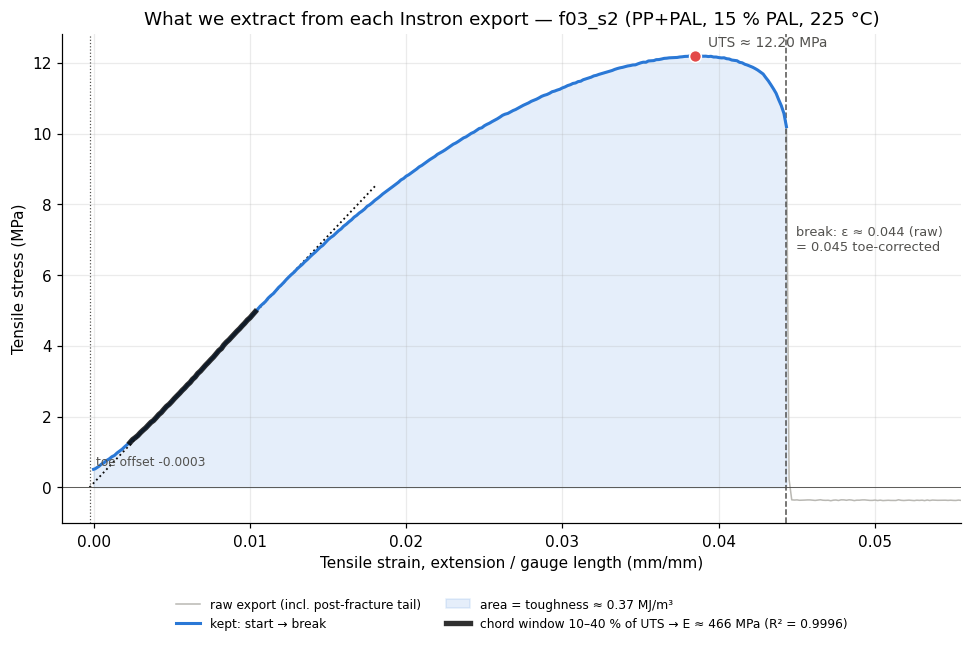

In [10]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_curve_anatomy"

PICK = "f03_s2"
row = summary.set_index("specimen_id").loc[PICK].copy(); row["specimen_id"] = PICK
plots.instron_anatomy(curves[PICK], row, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

### 5.2 All curves, one panel per formulation
Replicates overlaid up to the break (solid = main session, dashed = follow-up `_1` specimen). Shared stress
axis; strain axis per panel — note the TPU filament stretches to ~120 % vs. 2–7 % for PP / HDPE.

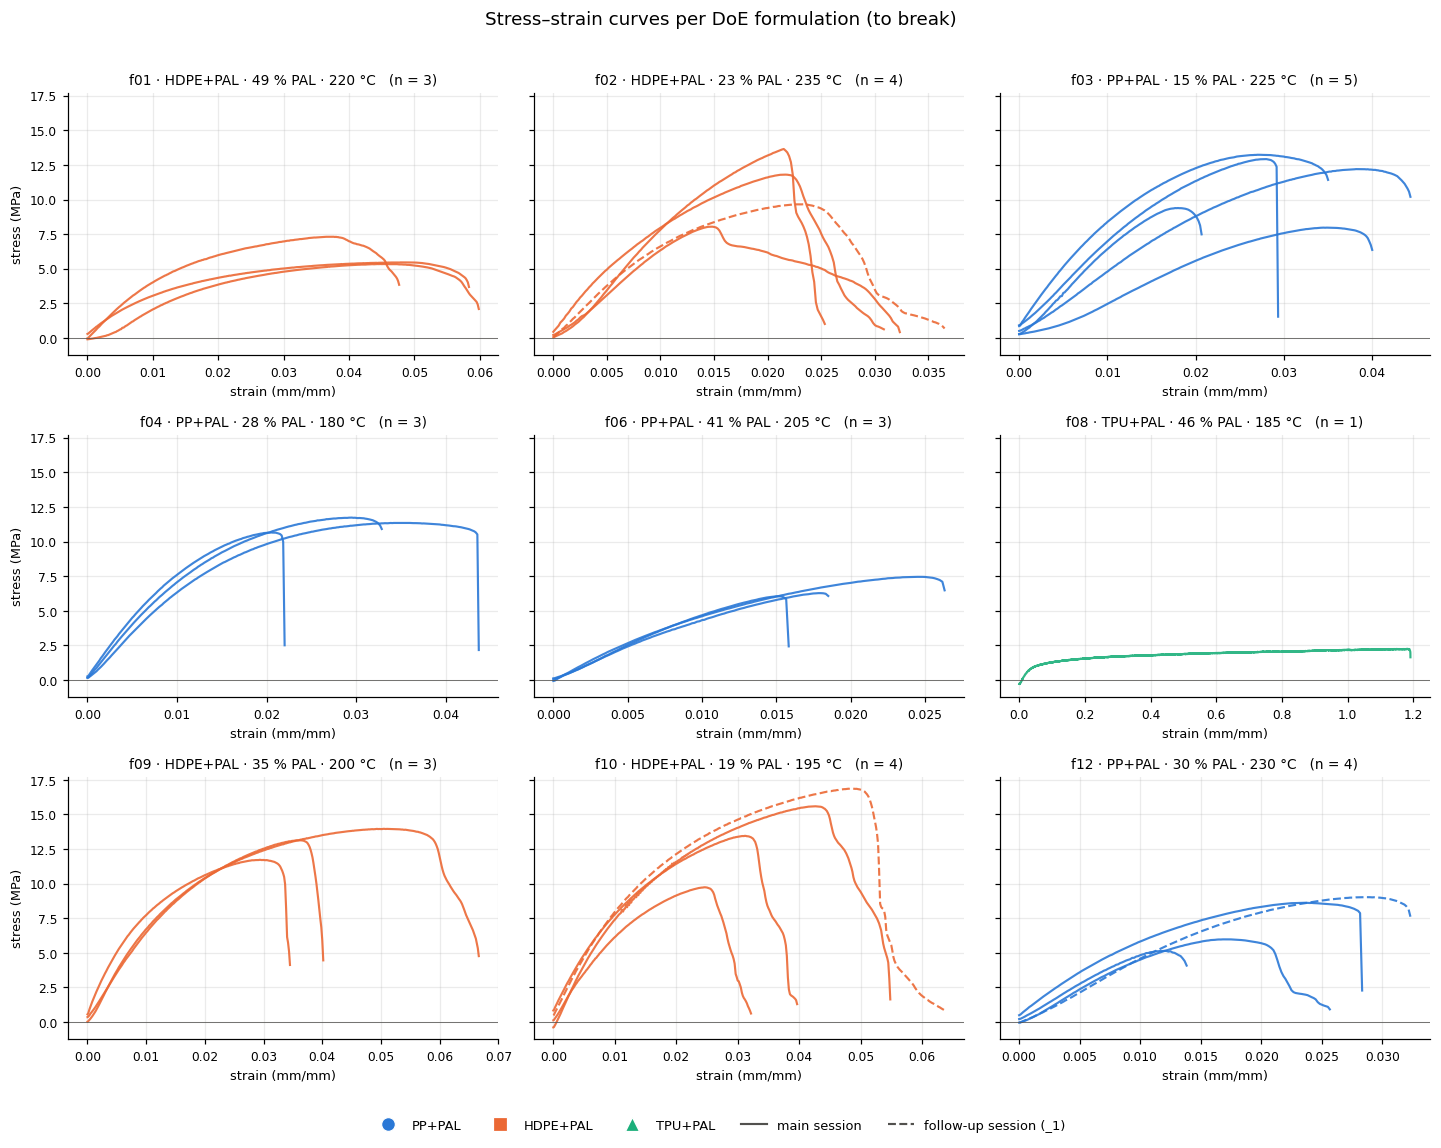

In [11]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_curves_grid"

plots.instron_curves_grid(curves, summary, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

---
## 6 — Per-formulation statistics

### 6.1 Replicate mean ± std

In [12]:
SAVE_CSV = False                      # True -> write the per-formulation table to processed_data/tensile_doe/
CSV_NAME = "tensile_doe_by_formulation"

by_form = instron.by_formulation(summary)
if SAVE_CSV:
    by_form.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
by_form.round(3)

,formulation,polymer_system,pal_pct,extr_temp_C,n_specimens,n_sessions,diameter_mm_mean,young_modulus_MPa_mean,young_modulus_MPa_std,UTS_MPa_mean,UTS_MPa_std,strain_at_break_mean,strain_at_break_std,toughness_MJ_m3_mean,toughness_MJ_m3_std
0,1,HDPE+PAL,49,220,3,1,1.950,347.105,79.554,6.037,1.106,0.055,0.006,0.245,0.015
1,2,HDPE+PAL,23,235,4,2,1.625,808.592,132.392,10.788,2.454,0.031,0.005,0.195,0.029
2,3,PP+PAL,15,225,5,1,1.700,582.799,208.019,11.142,2.335,0.034,0.009,0.256,0.102
3,4,PP+PAL,28,180,3,1,1.617,766.855,78.549,11.246,0.546,0.033,0.011,0.270,0.109
4,6,PP+PAL,41,205,3,1,1.817,509.760,18.423,6.592,0.754,0.020,0.006,0.086,0.040
5,8,TPU+PAL,46,185,1,1,1.550,24.057,NaN,2.247,NaN,1.190,NaN,2.183,NaN
6,9,HDPE+PAL,35,200,3,1,1.750,751.091,114.539,12.937,1.132,0.048,0.017,0.454,0.215
7,10,HDPE+PAL,19,195,4,2,1.600,751.377,59.928,13.908,3.117,0.048,0.014,0.456,0.220
8,12,PP+PAL,30,230,4,2,1.788,543.888,48.601,7.190,1.921,0.025,0.008,0.128,0.070


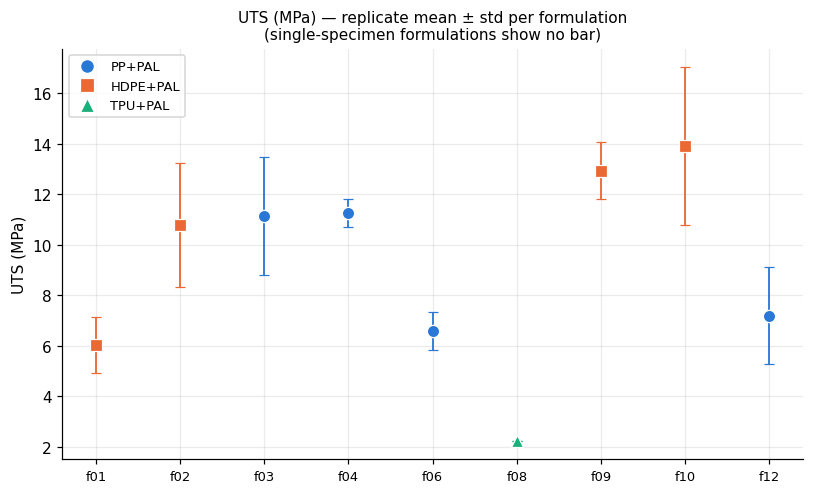

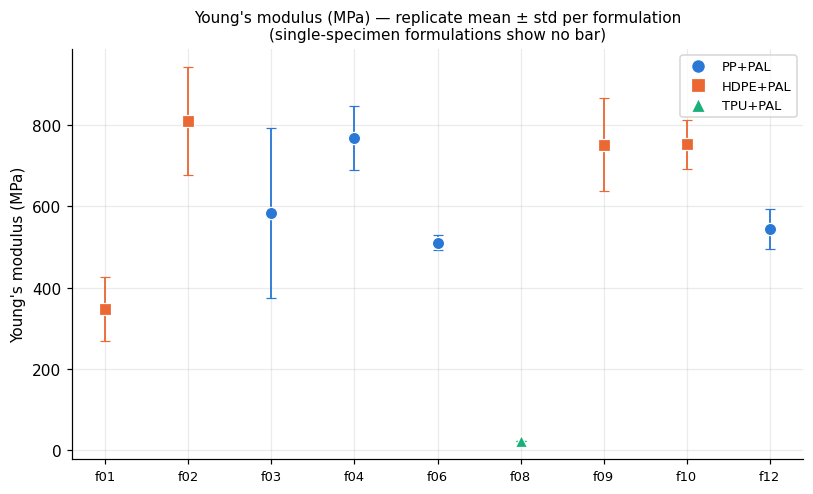

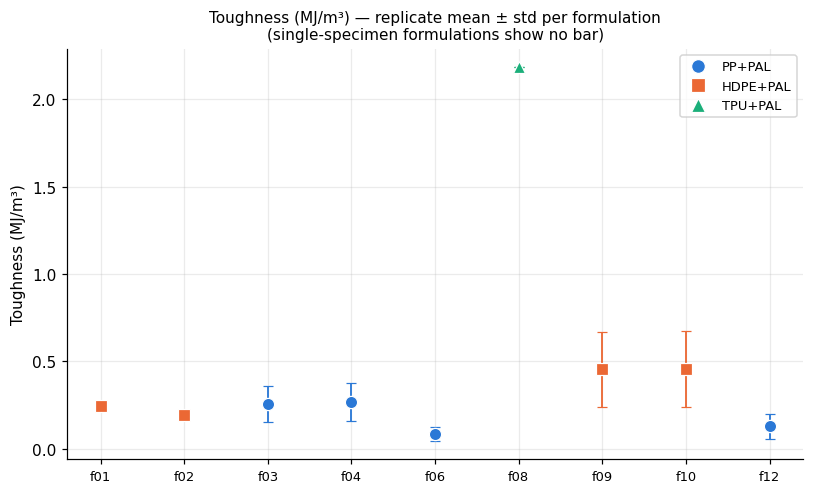

In [13]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_props_by_formulation"   # with SEPARATE_PLOTS: <FIG_NAME>_<property>.png, one per figure
SEPARATE_PLOTS = True   # False: three panels side by side · True: one figure per property (each plt.show()-n)
plots.props_by_formulation(by_form, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"),
                           separate=SEPARATE_PLOTS)

### 6.2 Reproducibility — coefficient of variation
`CV = std / mean` per formulation (red = noisier). Same table style as the June delivery, optionally saved as CSV and / or XLSX (shaded).

In [14]:
SAVE_CSV = False                      # True -> write the CV table to processed_data/tensile_doe/
CSV_NAME = "tensile_doe_cv_by_formulation"
SAVE_XLSX = False                     # True -> write the shaded table as an Excel file (same folder)
XLSX_NAME = "tensile_doe_cv_by_formulation"

cv = instron.cv_by_formulation(summary)
if SAVE_CSV:
    cv.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
styled = plots.style_cv(cv)
if SAVE_XLSX:
    styled.to_excel(io.save_path(p.tensile_doe, XLSX_NAME, ext=".xlsx"), sheet_name="CV_by_formulation",
                    index=False, engine="openpyxl")
styled

,Formulation,Polymer,PAL %,Extr. temp (°C),n,Young's modulus mean (MPa),CV Young's modulus (%),UTS mean (MPa),CV UTS (%),Toughness mean (MJ/m³),CV toughness (%)
0,1,HDPE+PAL,49,220,3,347,22.9,6.04,18.3,0.25,6.0
1,2,HDPE+PAL,23,235,4,809,16.4,10.79,22.7,0.19,14.9
2,3,PP+PAL,15,225,5,583,35.7,11.14,21.0,0.26,40.0
3,4,PP+PAL,28,180,3,767,10.2,11.25,4.9,0.27,40.3
4,6,PP+PAL,41,205,3,510,3.6,6.59,11.4,0.09,46.3
5,8,TPU+PAL,46,185,1,24,nan,2.25,nan,2.18,nan
6,9,HDPE+PAL,35,200,3,751,15.2,12.94,8.8,0.45,47.4
7,10,HDPE+PAL,19,195,4,751,8.0,13.91,22.4,0.46,48.3
8,12,PP+PAL,30,230,4,544,8.9,7.19,26.7,0.13,54.5


---
## 7 — Properties vs. design factors

With 9 formulations spread over the LHS there is no full grid to heat-map (unlike the June 3 × 4 design), so
each property is shown against each factor (top: PAL %, bottom: temperature; small = specimens, large =
formulation means), then placed in the PAL × temperature plane with fill = magnitude.

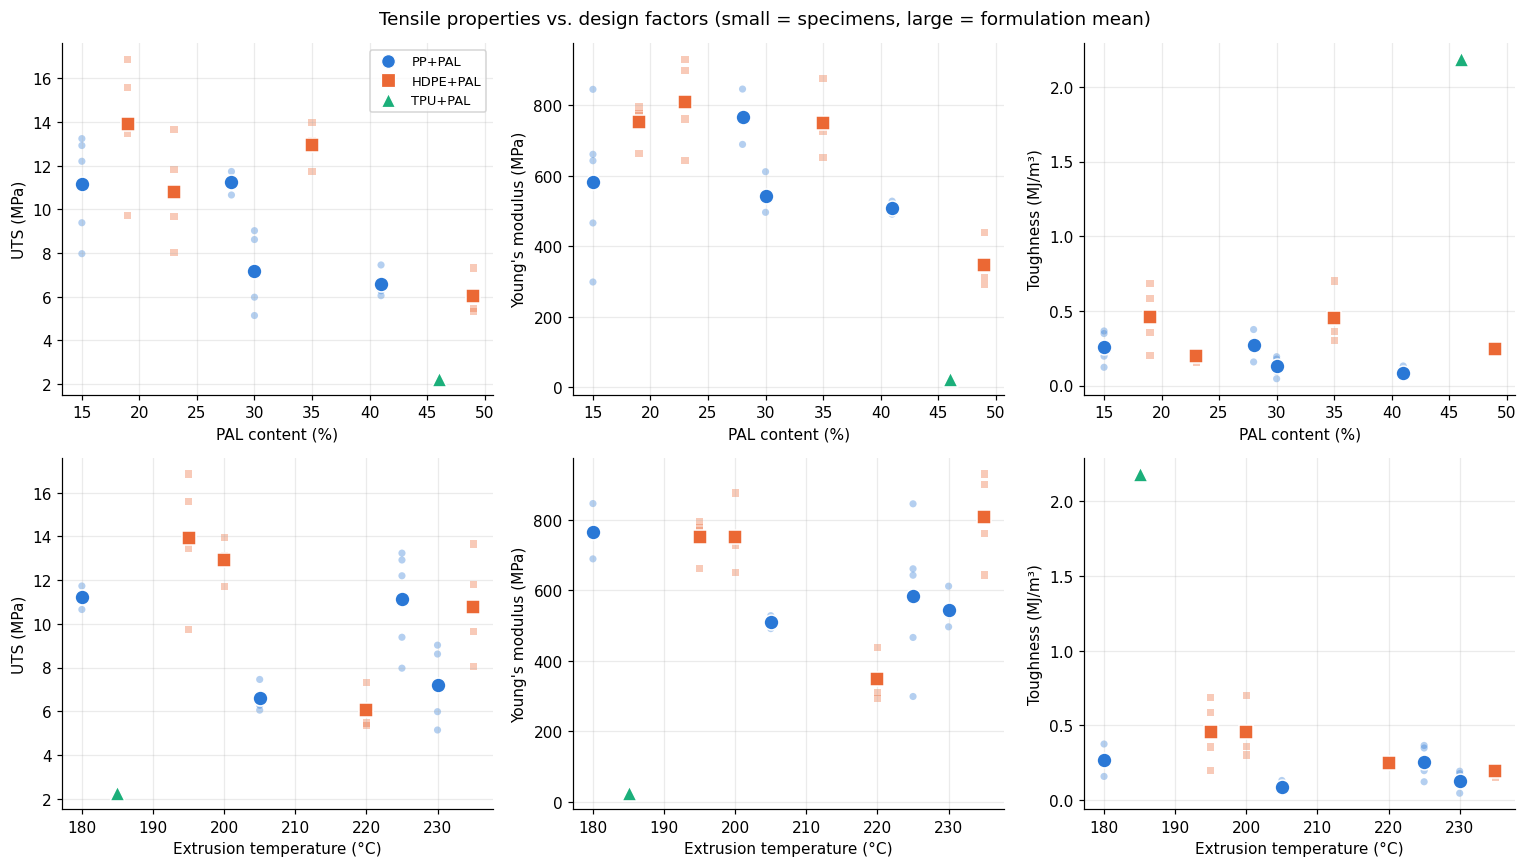

In [15]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_props_vs_factors"

plots.props_vs_factors(summary, by_form, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

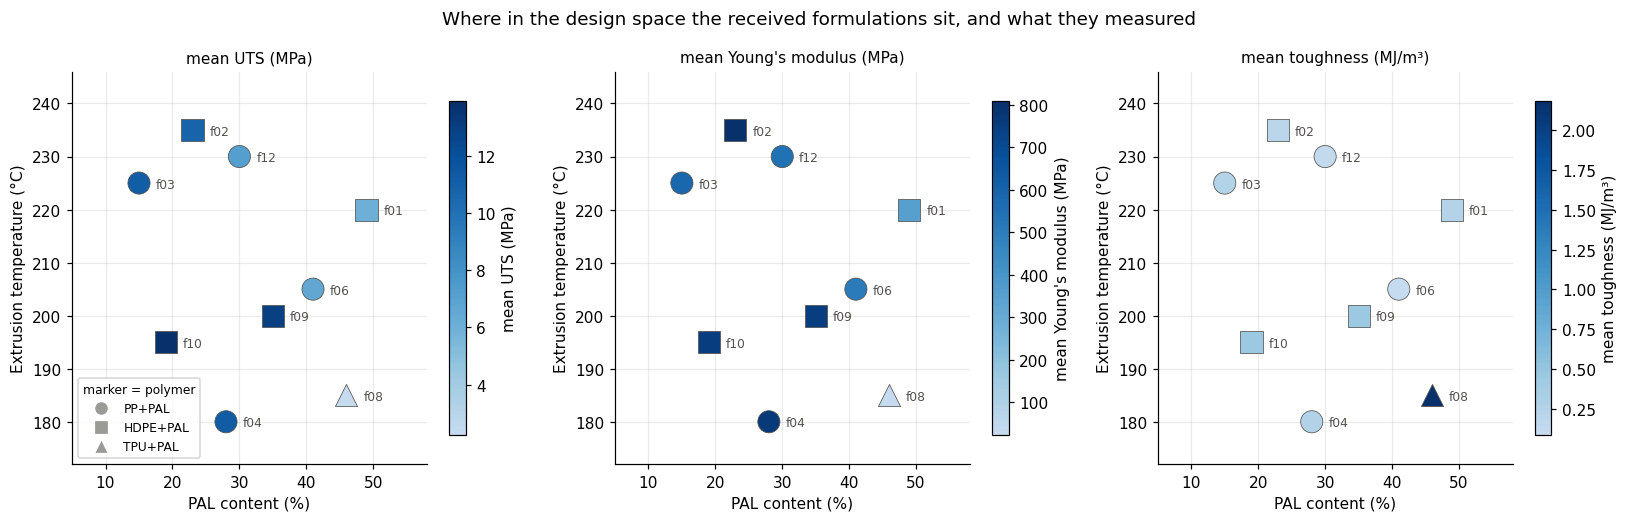

In [16]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_design_space"

plots.design_space_bubbles(by_form, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

---
## 8 — Objective correlations (multi-objective check)

Repeat of the June check on the new material set. The single TPU specimen (very low UTS, very high toughness)
dominates the linear statistic, so it is reported with and without it.

UTS vs toughness (all specimens, n=30): Pearson r = -0.071 (p=0.709) · Spearman ρ = 0.546
UTS vs toughness (PP + HDPE only, n=29): Pearson r = 0.778 (p=0.000) · Spearman ρ = 0.712

Pearson matrix, PP + HDPE only:
            UTS  Modulus  Toughness
UTS        1.00     0.73       0.78
Modulus    0.73     1.00       0.32
Toughness  0.78     0.32       1.00


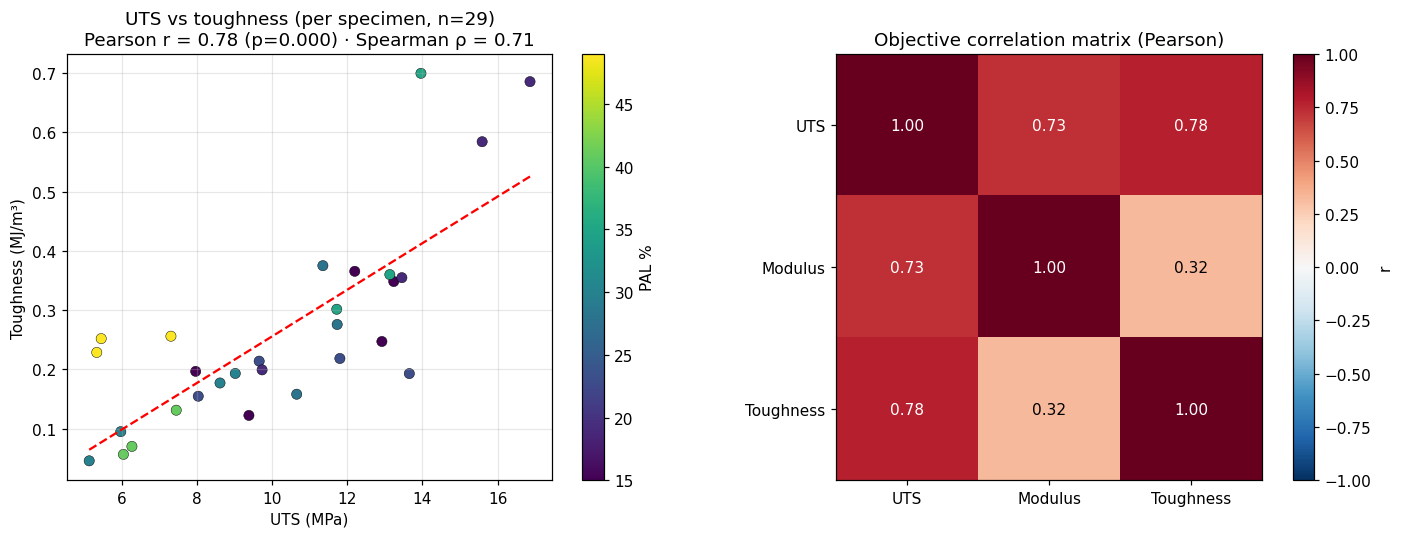

In [17]:
SAVE_CSV = False                      # True -> <CSV_NAME>.csv (all specimens) + <CSV_NAME>_pp_hdpe.csv in processed_data/tensile_doe/
CSV_NAME = "objective_correlations"
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_uts_toughness_correlation"

corr = tensile.objective_correlations(summary)
st_all = tensile.uts_toughness_stats(summary)
no_tpu = summary[summary["polymer_system"] != "TPU+PAL"]
st_pp_hdpe = tensile.uts_toughness_stats(no_tpu)
corr_pp_hdpe = tensile.objective_correlations(no_tpu)
if SAVE_CSV:
    corr_path = io.save_path(p.tensile_doe, CSV_NAME, ext=".csv")
    corr.to_csv(corr_path)
    corr_pp_hdpe.to_csv(corr_path.with_name(f"{corr_path.stem}_pp_hdpe{corr_path.suffix}"))
for lab, st in [("all specimens", st_all), ("PP + HDPE only", st_pp_hdpe)]:
    print(f"UTS vs toughness ({lab}, n={st['n']}): Pearson r = {st['pearson_r']:.3f} "
          f"(p={st['pearson_p']:.3f}) · Spearman ρ = {st['spearman_rho']:.3f}")
print("\nPearson matrix, PP + HDPE only:")
print(corr_pp_hdpe.round(2))
plots.correlation(no_tpu, corr_pp_hdpe, st_pp_hdpe,
                  save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

### 8.1 Pareto front — UTS × Young's modulus × toughness
All three responses are to be **maximised**. A formulation is *Pareto-optimal* (non-dominated) when no other
formulation is at least as good on all three and strictly better on one. `tensile.pareto_front` runs the
non-dominated sorting on the replicate means: `pareto_rank` 1 = on the front, 2 = on the front once rank 1 is
removed, …; `dominated_by` lists the formulations that beat it on every objective.

In [18]:
SAVE_CSV = False                      # True -> write the Pareto table to processed_data/tensile_doe/
CSV_NAME = "pareto_front"

OBJECTIVES = ["UTS_MPa_mean", "young_modulus_MPa_mean", "toughness_MJ_m3_mean"]
pareto = tensile.pareto_front(by_form, OBJECTIVES, label="formulation")
if SAVE_CSV:
    pareto.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
on_front = pareto.loc[pareto["pareto_optimal"], "formulation"]
print(f"Pareto-optimal on (UTS, modulus, toughness): {', '.join(f'f{f:02d}' for f in on_front)} "
      f"— {len(on_front)} of {len(pareto)} formulations")
(pareto[["formulation", "polymer_system", "pal_pct", "extr_temp_C", "n_specimens", *OBJECTIVES,
         "pareto_rank", "dominated_by"]]
    .sort_values(["pareto_rank", "formulation"]).round(3))

Pareto-optimal on (UTS, modulus, toughness): f02, f04, f08, f10 — 4 of 9 formulations


,formulation,polymer_system,pal_pct,extr_temp_C,n_specimens,UTS_MPa_mean,young_modulus_MPa_mean,toughness_MJ_m3_mean,pareto_rank,dominated_by
1,2,HDPE+PAL,23,235,4,10.788,808.592,0.195,1,
3,4,PP+PAL,28,180,3,11.246,766.855,0.270,1,
5,8,TPU+PAL,46,185,1,2.247,24.057,2.183,1,
7,10,HDPE+PAL,19,195,4,13.908,751.377,0.456,1,
6,9,HDPE+PAL,35,200,3,12.937,751.091,0.454,2,10
2,3,PP+PAL,15,225,5,11.142,582.799,0.256,3,"4, 9, 10"
0,1,HDPE+PAL,49,220,3,6.037,347.105,0.245,4,"3, 4, 9, 10"
8,12,PP+PAL,30,230,4,7.190,543.888,0.128,4,"2, 3, 4, 9, 10"
4,6,PP+PAL,41,205,3,6.592,509.760,0.086,5,"2, 3, 4, 9, 10, 12"


The front lives in 3-D, so it is shown as its three pairwise projections. **Filled** = on the 3-objective front,
**hollow** = dominated; the stepped line is the 2-objective front of that panel alone — a filled marker sitting
below it is kept on the front by the third objective. Toughness is on a log axis (TPU is ~5× everything else);
error bars = replicate std.

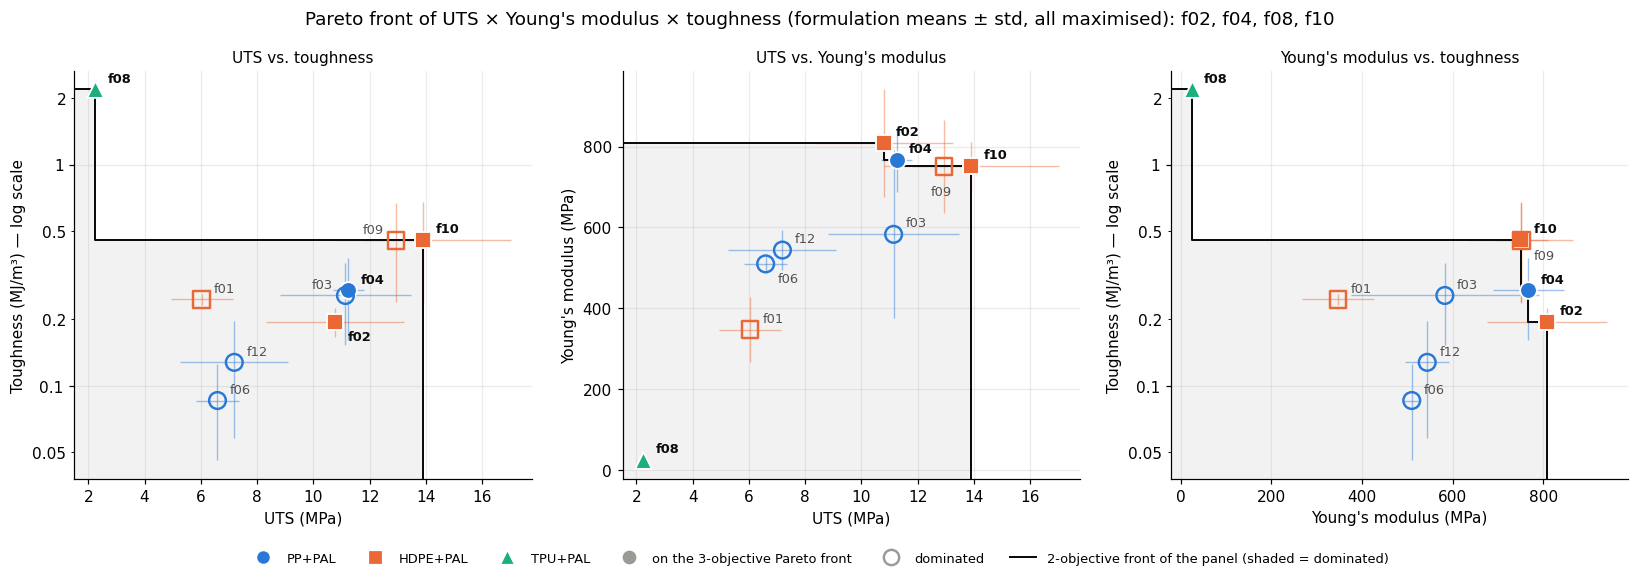

In [19]:
SAVE_FIG = False                      # True -> write the figure to processed_data/figures/
FIG_NAME = "doe_tensile_pareto_front"

plots.pareto_front(pareto, save=io.save_path(p.figures, FIG_NAME, SAVE_FIG, ".png"))

**Reading the front**

* **f10** (HDPE · 19 % PAL · 195 °C) is the best rigid formulation on *both* UTS and toughness — consistent with the
  positive UTS–toughness correlation above, there is no strength-vs-toughness trade-off within PP / HDPE.
* The trade-off inside the rigid composites is against **stiffness**: **f02** (HDPE · 23 % · 235 °C) is the stiffest
  (+8 % modulus vs. f10) but gives up 22 % UTS and 57 % toughness; **f04** (PP · 28 % · 180 °C) sits in between.
* **f08** (TPU) is on the front through toughness alone (5× higher, at 1/6 of the UTS and 1/30 of the modulus) — the
  real trade-off is *between polymer classes*. It rests on a **single specimen**.
* **f09** is rank 2, but dominated only by f10 and only by 1.0 MPa / 0.3 MPa / 0.002 MJ/m³ — far inside the
  replicate std, so the two are indistinguishable and f09 is effectively on the front too.
* The PAL-rich formulations (f01 · 49 %, f06 · 41 %) are the deepest ranks: high PAL is dominated on every objective.

The sorting uses replicate means only; the ± 1 std bars of neighbouring formulations overlap, so membership is
provisional — a noise-aware front from the heteroscedastic GP posterior is the natural next step.

---
## 9 — Modeling-ready dataset

One row per specimen with the DoE inputs (polymer system, PAL %, temperature, recycle level) and the three
responses — the table the heteroscedastic-noise LVGP will consume. `recycle_level` is left empty until the
level is confirmed. Optionally written as CSV (`SAVE_CSV`) and as an XLSX with the per-formulation sheet alongside (`SAVE_XLSX`).

In [20]:
SAVE_CSV = False                      # True -> write the per-specimen dataset to processed_data/tensile_doe/
CSV_NAME = "doe_tensile_dataset"
SAVE_XLSX = False                     # True -> Excel workbook: specimens + by_formulation + doe_coverage sheets
XLSX_NAME = "doe_tensile_dataset"

dataset_cols = ["formulation", "polymer_system", "pal_pct", "extr_temp_C", "recycle_level",
                "specimen_id", "session", "specimen", "diameter_mm",
                "young_modulus_MPa", "max_tensile_stress_MPa", "strain_at_break", "toughness_MJ_m3"]
dataset = summary[dataset_cols].copy()
if SAVE_CSV:
    dataset.to_csv(io.save_path(p.tensile_doe, CSV_NAME, ext=".csv"), index=False)
if SAVE_XLSX:
    with pd.ExcelWriter(io.save_path(p.tensile_doe, XLSX_NAME, ext=".xlsx"), engine="openpyxl") as xw:
        dataset.to_excel(xw, sheet_name="specimens", index=False)
        by_form.to_excel(xw, sheet_name="by_formulation", index=False)
        cov.to_excel(xw, sheet_name="doe_coverage", index=False)
print(f"{len(dataset)} rows · inputs: polymer_system, pal_pct, extr_temp_C, (recycle_level) · "
      f"responses: young_modulus_MPa, max_tensile_stress_MPa, toughness_MJ_m3")
dataset.round(3)

30 rows · inputs: polymer_system, pal_pct, extr_temp_C, (recycle_level) · responses: young_modulus_MPa, max_tensile_stress_MPa, toughness_MJ_m3


,formulation,polymer_system,pal_pct,extr_temp_C,recycle_level,specimen_id,session,specimen,diameter_mm,young_modulus_MPa,max_tensile_stress_MPa,strain_at_break,toughness_MJ_m3
0,1,HDPE+PAL,49,220,<NA>,f01_s1,0,1,1.75,438.326,7.312,0.048,0.256
1,1,HDPE+PAL,49,220,<NA>,f01_s2,0,2,2.05,310.867,5.459,0.060,0.252
2,1,HDPE+PAL,49,220,<NA>,f01_s3,0,3,2.05,292.121,5.340,0.057,0.229
3,2,HDPE+PAL,23,235,<NA>,f02_s1,0,1,1.40,930.202,13.650,0.024,0.193
4,2,HDPE+PAL,23,235,<NA>,f02_s2,0,2,1.70,899.481,11.804,0.032,0.218
5,2,HDPE+PAL,23,235,<NA>,f02_s3,0,3,1.75,643.374,8.039,0.032,0.155
6,2,HDPE+PAL,23,235,<NA>,f02_1_s1,1,1,1.65,761.310,9.658,0.036,0.214
7,3,PP+PAL,15,225,<NA>,f03_s1,0,1,1.70,845.453,13.236,0.036,0.348
8,3,PP+PAL,15,225,<NA>,f03_s2,0,2,1.40,466.142,12.199,0.045,0.365
9,3,PP+PAL,15,225,<NA>,f03_s3,0,3,1.75,661.035,9.385,0.021,0.122


---
## 10 — Outputs

Files currently on disk from this delivery — written earlier or by the cells above whose save switch is `True`
(a run with every switch off leaves this list unchanged).

In [21]:
for f in sorted(p.tensile_doe.iterdir()):
    if f.is_file():
        print(f.relative_to(p.root))
    else:                                   # a curves folder (any CURVES_DIR): just count its files
        print(f"{f.relative_to(p.root)}/  ({len(list(f.glob('*.csv')))} tidy curves)")
for f in sorted(p.figures.glob("doe_tensile_*")):      # figures that kept the default doe_tensile_ prefix
    print(f.relative_to(p.root))

processed_data/tensile_doe/curves/  (30 tidy curves)
processed_data/tensile_doe/delivery_catalogue.csv
processed_data/tensile_doe/doe_coverage.csv
processed_data/tensile_doe/doe_tensile_dataset.csv
processed_data/tensile_doe/doe_tensile_dataset.xlsx
processed_data/tensile_doe/objective_correlations.csv
processed_data/tensile_doe/objective_correlations_pp_hdpe.csv
processed_data/tensile_doe/pareto_front.csv
processed_data/tensile_doe/tensile_doe_by_formulation.csv
processed_data/tensile_doe/tensile_doe_cv_by_formulation.csv
processed_data/tensile_doe/tensile_doe_cv_by_formulation.xlsx
processed_data/tensile_doe/tensile_doe_summary.csv
processed_data/figures/doe_tensile_coverage.png
processed_data/figures/doe_tensile_curve_anatomy.png
processed_data/figures/doe_tensile_curves_grid.png
processed_data/figures/doe_tensile_design_space.png
processed_data/figures/doe_tensile_pareto_front.png
processed_data/figures/doe_tensile_props_by_formulation.png
processed_data/figures/doe_tensile_props_b

---
## Summary

**Delivery vs. DoE**
* 30 specimens over **9 of 12 formulations**. All three missing formulations are TPU+PAL (f05, f07, f11) and
  the one TPU formulation delivered (f08) has a single specimen → the polymer factor is effectively two-level
  for now (LVGP wants ≥ 3 populated levels).
* PP+PAL and HDPE+PAL are complete (3–5 specimens each); PAL × temperature coverage is as designed.
* Recycle level is not encoded in the delivery (assumed as-extruded, to confirm); no rheology in this batch.

**Properties** (replicate means)
* UTS spans ~6–14 MPa for the PP / HDPE composites. Strongest: the low-PAL HDPE formulations
  (f10 · 19 % PAL / 195 °C, f09 · 35 % / 200 °C) and the low-PAL PP ones (f03, f04 ≈ 11 MPa). Weakest: the
  PAL-rich ones (f01 · 49 % PAL HDPE, f06 · 41 % PAL PP) — **more PAL → lower UTS and modulus** for both matrices.
* Young's modulus: HDPE 750–810 MPa up to 35 % PAL, dropping to ~350 MPa at 49 %; PP 510–770 MPa.
* TPU f08 behaves as an elastomer: UTS 2.2 MPa, ~120 % strain, toughness 2.2 MJ/m³ (≈ 5× any other formulation).

**Noise** — CV of UTS 5–27 %, modulus 4–36 %, toughness 6–55 %. Toughness is again the noisiest response
(it is driven by the break strain); filament diameter varying 1.40–2.05 mm *within* a formulation is a likely
contributor. Input-dependent scatter → the heteroscedastic-noise GP remains the right tool.

**Objectives** — Without the TPU point, UTS and toughness are strongly correlated in this batch
(Pearson 0.78, Spearman 0.71; June batch: 0.40 / 0.51), i.e. less of a trade-off than before. The single TPU
specimen flips the Pearson sign, so the correlation is polymer-dependent.
On the replicate means the **Pareto front of UTS × modulus × toughness** is f02, f04, f10 (rigid: stiffest /
balanced / strongest-and-toughest) plus TPU f08 (toughness only, n = 1); f09 is a statistical tie with f10. Within
PP / HDPE the only trade-off is stiffness vs. strength + toughness; the large one is between polymer classes.

**To raise with Anupam** — the TPU formulations f05 / f07 / f11 and ≥ 2 more f08 specimens; which recycle
level these samples are; rheology for the received formulations; the 5× / 10× series.